# 01 — Pitcher data exploration

Reads processed tables produced by `src/run_pipeline.py`; does not modify data.

* **Statcast**: MLB regular season 2025-06-01 to 06-07 (pipeline sample, not evidence of model quality).
* **College TrackMan**: Pifer (2024), Mendeley Data, DOI 10.17632/xfnz6mkdzm.3, CC BY 4.0. Analysed separately; never pooled with Statcast.

Units: mph, rpm, inches for movement (arm-side +), feet for release/plate (catcher's view). Every rate shows numerator and denominator.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, Markdown, display
import pitcher_analysis as pa
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
sc = pa.load('../data/processed/pitches.parquet')
tm = pa.load('../data/processed/trackman_pitches.parquet')
print(f'Statcast retained: {len(sc):,} pitches, {sc.game_pk.nunique()} games, {sc.pitcher_id.nunique()} pitchers')
print(f'TrackMan retained: {len(tm):,} pitches, {tm.game_pk.nunique()} games, {tm.pitcher_id.nunique()} pitchers')

Statcast retained: 27,036 pitches, 94 games, 418 pitchers
TrackMan retained: 3,344 pitches, 21 games, 32 pitchers


## Data quality
Full audits: `reports/data_audit.md`, `reports/trackman_audit.md`. Row status:

In [2]:
raw_sc = pd.read_parquet('../data/processed/pitches.parquet'); raw_tm = pd.read_parquet('../data/processed/trackman_pitches.parquet')
pd.concat({'statcast': raw_sc.groupby(['status','status_reason']).size(), 'trackman': raw_tm.groupby(['status','status_reason']).size()}).rename('rows').to_frame()

rows
         status   status_reason               
statcast excluded non_competitive_pitch     85
         retained                        27036
trackman retained                         3344

## Swing outcomes (eligible ordinary swings only)

In [3]:
def swing_table(df):
    return df.groupby('pitch_group').agg(pitches=('pitch_key','size'), swings=('eligible_swing','sum'),
                                         misses=('is_miss', lambda s: int((s==1).sum()))).assign(whiff_rate=lambda t: (t.misses/t.swings).round(3))
pd.concat({'MLB (Statcast)': swing_table(sc), 'College (TrackMan, operator tag)': swing_table(tm)})

pitches  swings  misses  whiff_rate
                                 pitch_group                                     
MLB (Statcast)                   breaking        8434    3952    1241       0.314
                                 cutter          2088    1026     213       0.208
                                 fastball       12797    6136     973       0.159
                                 offspeed        3687    1845     563       0.305
                                 other             30      13       1       0.077
College (TrackMan, operator tag) breaking        1163     462     171        0.37
                                 cutter            47      17       7       0.412
                                 fastball        1746     747     138       0.185
                                 offspeed         387     180      64       0.356
                                 other              1       1       1         1.0

## All pitchers: summary by pitch type
`low_sample_*` flags use the configurable display heuristics (30 pitches, 50 swings); they are not reliability guarantees.

In [4]:
summary = pd.read_csv('../reports/pitcher_summary.csv')
cols = ['pitcher_name','p_throws','pitch_type_raw','pitches','usage','velo_mean','spin_mean','ivb_in','hmov_arm_in','swings','misses','whiff_rate','whiff_lo','whiff_hi','low_sample_swings']
summary.query('pitches >= 100')[cols].sort_values('pitches', ascending=False).head(15).round(3)

,pitcher_name,p_throws,pitch_type_raw,pitches,usage,velo_mean,spin_mean,ivb_in,hmov_arm_in,swings,misses,whiff_rate,whiff_lo,whiff_hi,low_sample_swings
153,"Gausman, Kevin",R,FF,107,0.535,93.871,2232.729,16.895,10.628,56,3,0.054,0.018,0.146,False
422,"Castillo, Luis",R,FF,101,0.526,95.652,2184.564,12.456,12.910,62,12,0.194,0.114,0.308,False
1342,"Parker, Mitchell",L,FF,101,0.678,93.259,2183.594,18.128,4.896,56,6,0.107,0.050,0.215,False


## Detailed MLB pitcher report
Selection rule: most pitches among pitchers with ≥ 2 games (coverage, not quality). Full text: `reports/pitcher_analysis.md`.

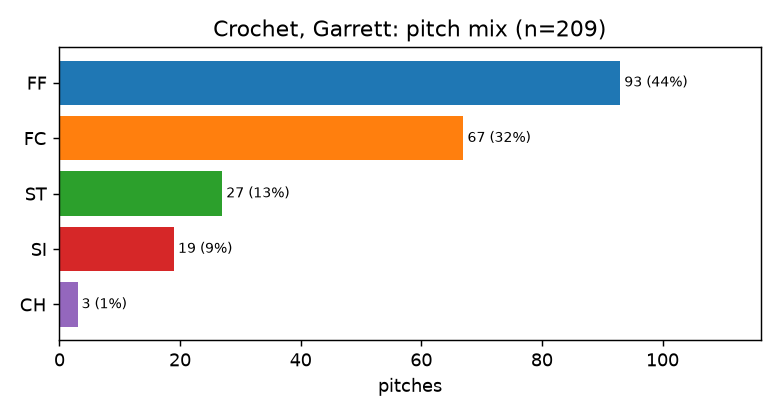

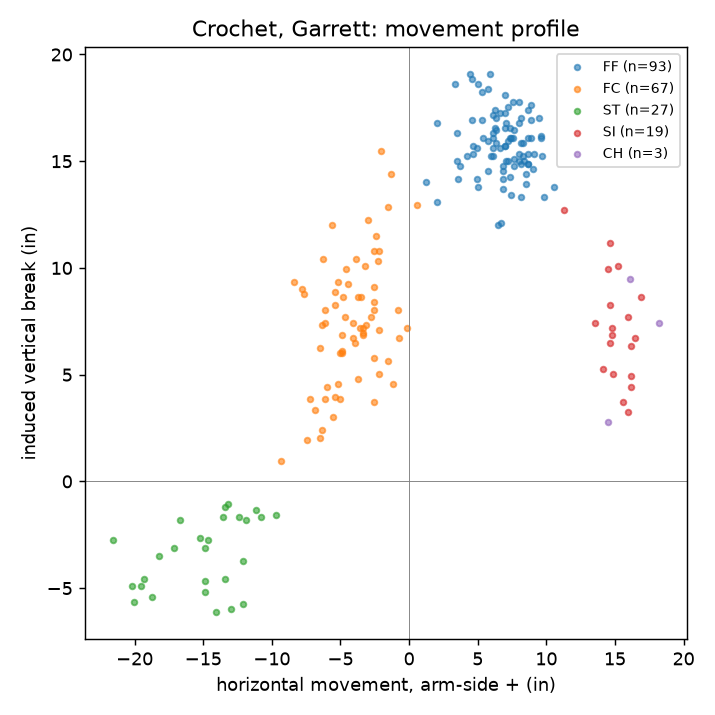

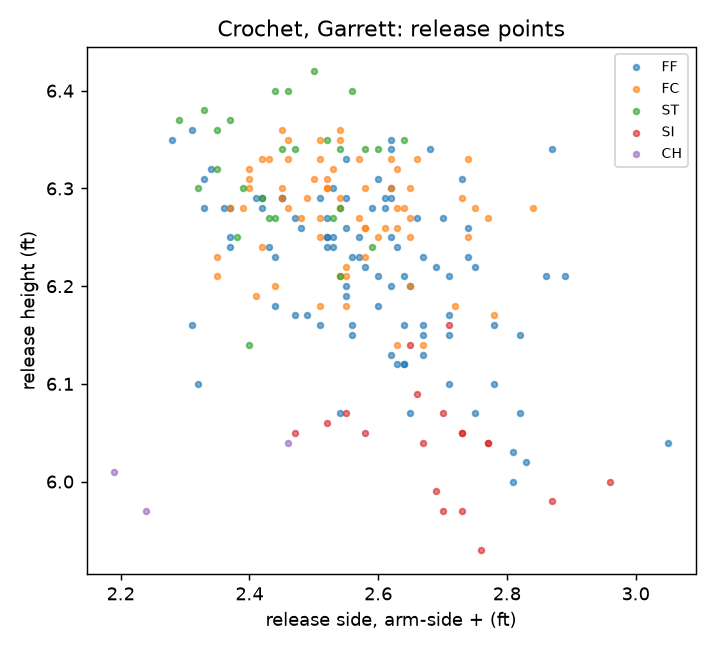

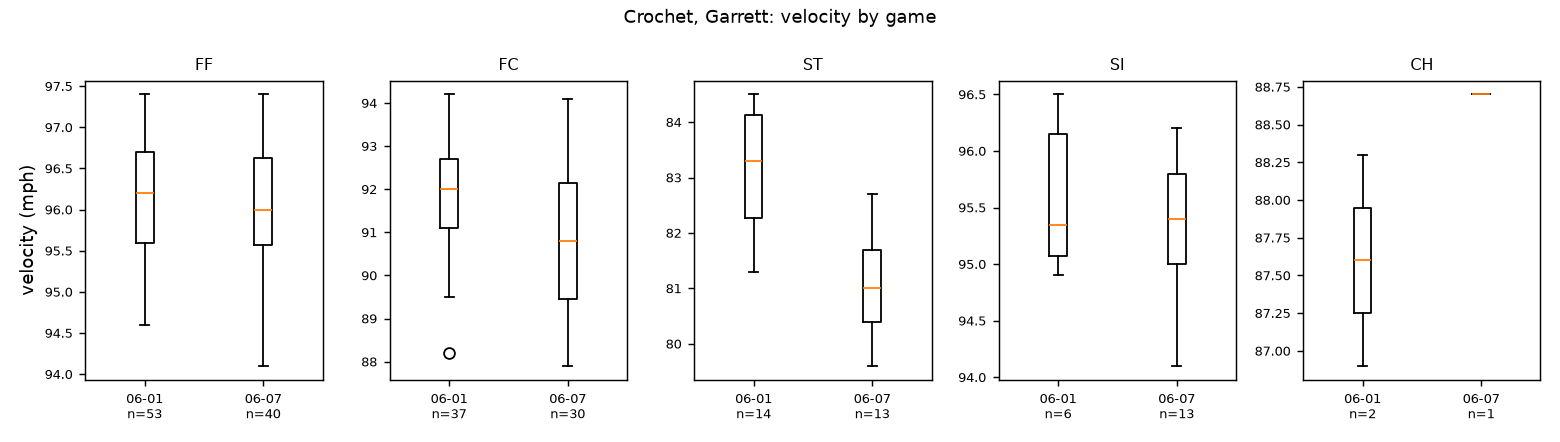

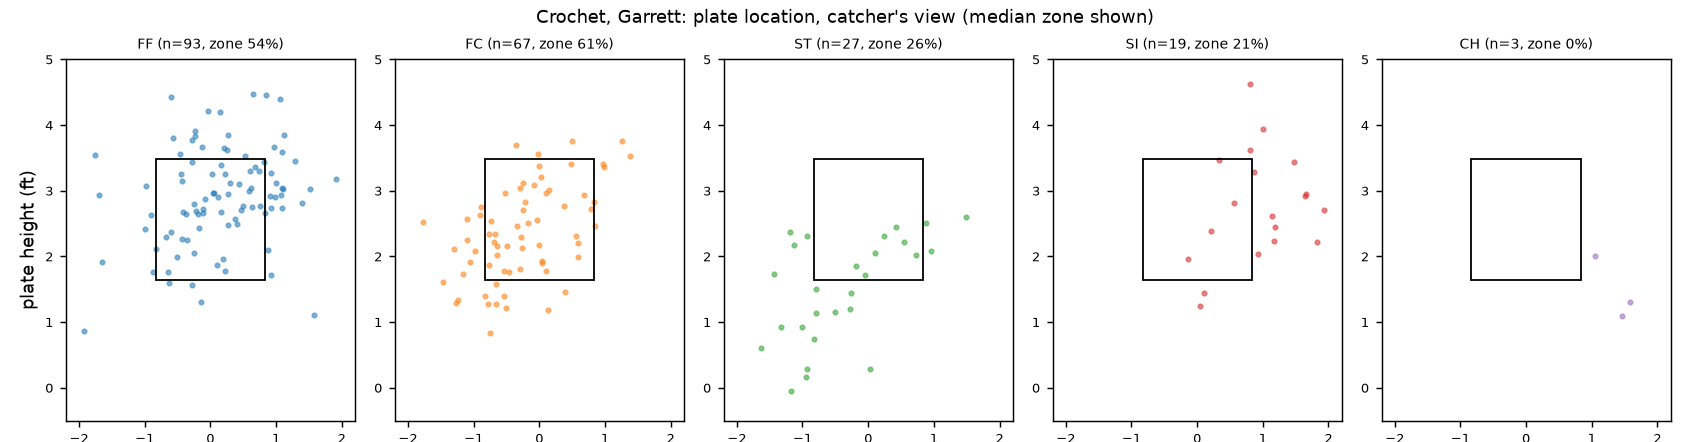

In [5]:
for f in ['676979_pitch_mix', '676979_movement', '676979_release', '676979_velocity_by_game', '676979_location']:
    display(Image(f'../reports/figures/{f}.png'))

## College TrackMan: the same descriptive code on the other source
This is descriptive only. The pitchers are from one program, mostly facing their own teammates in scrimmages, so no norms or peer rankings.

In [6]:
overall_tm, by_type_tm, _ = pa.pitcher_tables(tm)
top = overall_tm.sort_values('pitches', ascending=False).head(8)[['pitcher_id','p_throws','pitches','games','velo_mean','swings','misses','whiff_rate','whiff_lo','whiff_hi']]
top.round(3)

,pitcher_id,p_throws,pitches,games,velo_mean,swings,misses,whiff_rate,whiff_lo,whiff_hi
21,1000097856,L,234,7,84.526,92,19,0.207,0.136,0.300
17,1000064685,R,225,7,85.826,93,36,0.387,0.294,0.489
31,1000187700,L,224,10,77.946,92,20,0.217,0.145,0.312
23,1000103199,R,202,7,85.290,80,19,0.238,0.158,0.341
7,1000036180,R,197,6,88.118,86,27,0.314,0.226,0.418
5,10023185,R,196,8,82.527,75,13,0.173,0.104,0.274
8,1000036206,R,193,6,84.250,88,25,0.284,0.200,0.386
2,691205,R,187,6,89.492,89,24,0.27,0.188,0.370


In [7]:
pid = int(top.iloc[0].pitcher_id)
by_type_tm[by_type_tm.pitcher_id == pid][['pitch_type_raw','pitches','usage','velo_mean','velo_sd','spin_mean','ivb_in','hmov_arm_in','release_z_sd_in','swings','misses','whiff_rate']].round(2)

,pitch_type_raw,pitches,usage,velo_mean,velo_sd,spin_mean,ivb_in,hmov_arm_in,release_z_sd_in,swings,misses,whiff_rate
72,ChangeUp,22,0.09,79.65,2.48,1772.88,-2.88,15.98,2.02,7,0,0.0
73,Fastball,152,0.65,88.01,1.69,2040.43,8.53,13.51,2.73,57,8,0.14
74,Knuckleball,1,0.00,77.39,NaN,2176.56,3.73,-15.19,NaN,1,1,1.0
75,Slider,59,0.25,77.49,1.38,2217.46,-1.50,-10.60,2.28,27,10,0.37


## What this does and does not show

* **Observed:** repertoire, tracking summaries, and whiff rates with explicit denominators and Wilson 95% intervals.
* **Not shown:** causes, time trends (one week; college dates unverified), command accuracy (no catcher targets), or model predictions.
* **Next:** expand Statcast to the 2025 season, lock labels and splits, keep 2026 sealed as the final test.